# E0: do failed grasps hold the gripper at the wrong angle?
**VLA direction** · Pipeline v3, step E0 · LIBERO-PRO, Object suite · 20 Nov 2026 · from existing logs, nothing new was run

- **The question:** Pipeline v3 adds the gripper orientation to the plan, read from a directional interaction
  affordance map. That is only worth it on this suite if failed grasps close the gripper at a different angle
  from the held ones and from the demonstrations of the same object.
- **Pass criterion (agreed 19 Nov):** the median angle between a failed grasp and the nearest demonstrated grasp of
  the same object is at least 10 degrees larger than for held grasps. If not, the orientation branch pauses on
  LIBERO-Object and is tested on a suite with handled objects (LIBERO-10) instead.
- **Real:** the replayed demonstrations of the ten LIBERO-Object tasks and the rollouts of the papers' protocol
  (50 starts per task, seeds 7, 8, 9) with the ten-task action head of 13 Nov (`s9_align_release10`).
- **ORACLE:** the plans of the `oracle` runs. Angles are in world coordinates, because the logs do not record
  object orientations yet; the objects stand upright.

```text
(1) how the demonstrations grasp each object
        ↓
(2) every rollout's first close command near the named object: held or not, and its angle to the demonstrations
        ↓
(3) what differs instead: how far from the object the gripper closes
        ↓
(4) the images at a few failed closes
```

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance_vla").is_dir())
sys.path.insert(0, str(ROOT))
from report import grasp_orientation_helpers as G

set_matplotlib_formats("jpeg")
RUNS = ROOT / "runs"
LIBERO_PRO = RUNS / "libero_pro"
SUITES = ["libero_object_swap", "libero_object_task"]
CONFIGS = {"map plan kept (g1 + s9)": "full_g1_hold_s9_seed{}", "oracle plan (s9)": "full_oracle_s9_seed{}"}
SEEDS = (7, 8, 9)

## 1. How the demonstrations grasp

The first held grasp of its own target in every replayed demonstration. *Tilt* is how far the fingers lean from
straight down. The *closing yaw spread* is how much the direction in which the fingers close varies about the
vertical between demonstrations of the same object.

In [2]:
demos = G.demo_grasps(sorted((RUNS / "plan_following" / "demos").glob("*.npz")))
reference = G.demo_rotations(demos)
print(f"{len(demos)} demonstrations with a held grasp of their target")
display(G.demo_spread(demos))

464 demonstrations with a held grasp of their target


,demos,tilt median (deg),tilt max (deg),"closing yaw spread, 90th pct (deg)"
object,,,,
alphabet_soup,47,4.5,12.9,9.9
bbq_sauce,48,4.4,21.3,17.5
butter,50,5.3,14.1,20.6
chocolate_pudding,50,5.0,12.6,9.9
cream_cheese,50,4.4,15.8,17.7
ketchup,20,6.0,15.0,6.9
milk,50,11.6,26.1,9.7
orange_juice,50,9.7,21.0,12.7
salad_dressing,49,5.8,15.7,6.7


## 2. Failed and held grasps against the demonstrations

One row per rollout: its first close command near the named object. It is *held* when the grasp registers within
0.75 s. The angle is to the nearest demonstrated grasp of the same object, counting a turn of 180 degrees about the
approach axis as the same grasp. All three seeds are pooled per configuration.

In [3]:
attempts = {}
for name, pattern in CONFIGS.items():
    attempts[name] = pd.concat([G.rollout_attempts(LIBERO_PRO / pattern.format(seed), SUITES, reference)
                                for seed in SEEDS], ignore_index=True)
    gap, passed = G.verdict(attempts[name])
    print(f"{name}: failed minus held, median angle {gap:.1f} deg -> {'PASS' if passed else 'does not pass'}")
    display(G.group_table(attempts[name]))

map plan kept (g1 + s9): failed minus held, median angle 1.4 deg -> does not pass


,episodes,angle_median,angle_p75,yaw_median,tilt_median
group,,,,,
"held, task solved",1778.0,2.3,3.9,0.2,3.0
"held, task failed",181.0,3.3,5.3,0.2,4.9
not held,835.0,3.7,7.4,0.3,4.9
no close near the target,206.0,NaN,NaN,NaN,NaN


oracle plan (s9): failed minus held, median angle 1.6 deg -> does not pass


,episodes,angle_median,angle_p75,yaw_median,tilt_median
group,,,,,
"held, task solved",2316.0,2.4,4.0,0.2,3.5
"held, task failed",103.0,2.6,4.9,0.3,5.7
not held,463.0,4.0,8.2,0.5,6.7
no close near the target,118.0,NaN,NaN,NaN,NaN


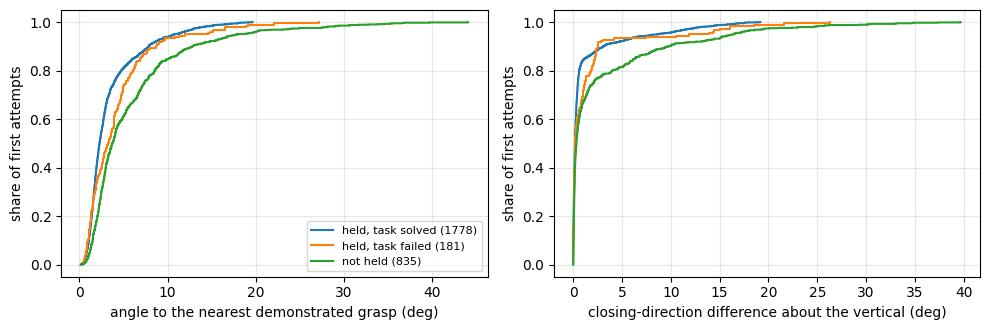

In [4]:
G.angle_figure(attempts["map plan kept (g1 + s9)"]);

Per object (median angle in degrees, number of rollouts in brackets), map plans kept:

In [5]:
display(G.per_object_table(attempts["map plan kept (g1 + s9)"]))

group,"held, task solved","held, task failed",not held
category,,,
alphabet_soup,1.9 (251),2.8 (8),2.9 (41)
bbq_sauce,5.6 (189),3.0 (5),3.0 (71)
butter,2.0 (202),1.9 (10),2.5 (42)
chocolate_pudding,1.9 (275),2.0 (9),2.0 (16)
cream_cheese,1.6 (280),3.7 (3),1.7 (17)
ketchup,4.6 (32),4.8 (63),5.1 (170)
milk,2.3 (116),2.4 (6),3.2 (165)
orange_juice,1.7 (101),1.3 (46),3.5 (77)
salad_dressing,4.0 (174),4.3 (24),2.4 (101)


## 3. What differs instead: where the gripper closes

The distance from the gripper to the named object's centre at the close command. It includes the object's own size,
so it is compared between outcomes of the same objects, not read as an error.

map plan kept (g1 + s9)


,count,25% (cm),50% (cm),75% (cm)
group,,,,
"held, task solved",1778.0,1.3,2.0,3.1
"held, task failed",181.0,3.0,4.1,4.4
not held,835.0,4.2,4.7,6.5


oracle plan (s9)


,count,25% (cm),50% (cm),75% (cm)
group,,,,
"held, task solved",2316.0,1.1,1.8,3.0
"held, task failed",103.0,2.9,3.6,4.4
not held,463.0,4.2,4.5,6.4


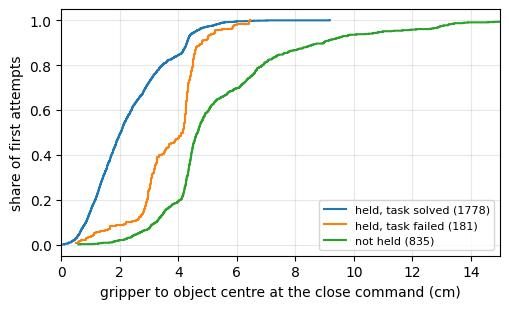

In [6]:
for name, table in attempts.items():
    print(name)
    display(G.distance_table(table))
G.distance_figure(attempts["map plan kept (g1 + s9)"]);

## 4. The images at some failed closes

Agent view and wrist view at the close command: among the failed attempts whose logs kept their images, the three
that closed furthest from the object and the three with the largest angle to the demonstrations (map plans kept).

37 failed first attempts kept their images


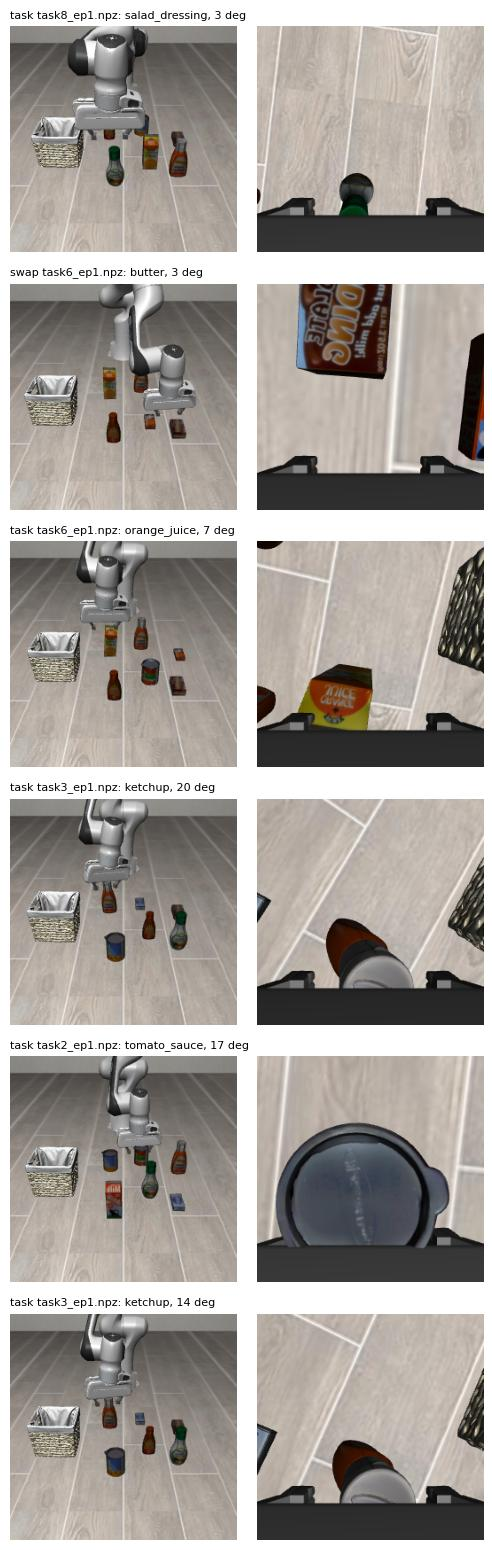

In [7]:
table = attempts["map plan kept (g1 + s9)"]
failed = G.with_images(table[table["group"] == "not held"], LIBERO_PRO)
print(f"{len(failed)} failed first attempts kept their images")
picked = pd.concat([failed.nlargest(3, "distance_m"), failed.nlargest(3, "angle_to_demo_deg")])
G.grasp_frames(picked, LIBERO_PRO);

## Conclusions

- **E0 does not pass on LIBERO-Object.** We compared each rollout's first close command near the named object with
  the nearest demonstrated grasp of that object.
  - Failed first grasps are only 1.4 degrees further from that demonstration than held ones with map plans kept,
    and 1.6 degrees with the oracle plan. The criterion asks for 10 degrees.
  - The closing direction about the vertical is within 0.5 degrees of a demonstration in every group (median).
  - The tilt differs by 2 to 3 degrees.
- **The demonstrations hardly vary either.** Every object is grasped from above:
  - the median tilt is 4 to 12 degrees;
  - the closing direction varies by 7 to 24 degrees between demonstrations of the same object (90th percentile).

  On this suite there is about one way to hold each object, and the policies reproduce it.
- **What differs is where the gripper closes.** Median distance from the gripper to the object's centre at the close
  command:

  | | held, task solved | not held |
  | --- | --- | --- |
  | map plans kept | 2.0 cm | 4.7 cm |
  | oracle plan | 1.8 cm | 4.5 cm |

  In the wrist images of failed closes, the fingers shut above or beside the object, not around it. Two objects
  stand out:
  - **ketchup:** in the two examples shown, the bottle is already lying on its side;
  - **tomato sauce:** about 10 degrees in every group, because its demonstrations vary most.
- **Consequence, by the rule agreed on 19 Nov (Pipeline v3, section 8):**
  - The orientation branch pauses on LIBERO-Object.
  - E3 (orientation upper bound) and E5 (orientation from the map) move to LIBERO-10, where mugs and moka pots have
    handles. The range of the "turn the orientation" counterfactual will be set there; on this suite ±45 degrees
    would lie far outside anything the demonstrations or the failures show.
  - On LIBERO-Object the position part of the interaction map comes first: interaction score, depth and finer
    features, then E1 and E2.
- **Not shown:**
  - Angles are in world coordinates, because object orientations are not logged yet. Step L adds them.
  - The closing distance is measured to the object's centre, so it includes the object's size. It is compared only
    between outcomes of the same objects.